## Ayda pirandakh
## Regression project - House Price Prediction


## imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline


## read Data

In [4]:
df = pd.read_csv("houseprice.csv.csv")

print("Initial shape:", df.shape)
df.head()


Initial shape: (3479, 8)


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


## Initial EDA(Befor cleaning)

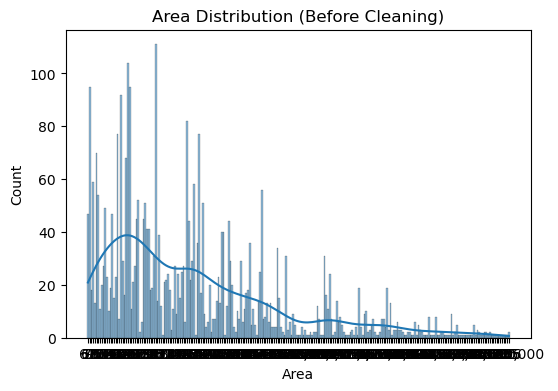

In [5]:
plt.figure(figsize=(6,4))
sns.histplot(df["Area"], bins=30, kde=True)
plt.title("Area Distribution (Before Cleaning)")
plt.show()


## Data cleaning

In [6]:
# Remove missing addresses
df = df.dropna(subset=["Address"])

# Clean Area column
df["Area"] = (
    df["Area"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

df["Area"] = pd.to_numeric(df["Area"], errors="coerce")

# Remove invalid Area
df = df.dropna(subset=["Area"])

# Remove outliers using IQR
Q1 = df["Area"].quantile(0.25)
Q3 = df["Area"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[(df["Area"] >= lower_bound) & (df["Area"] <= upper_bound)]

print("After cleaning shape:", df.shape)


After cleaning shape: (3219, 8)


## EDA (After Cleaning)

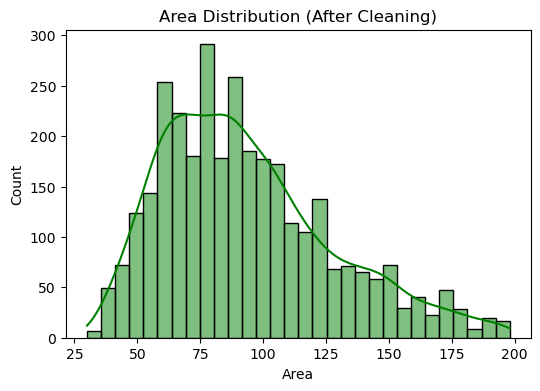

In [7]:
plt.figure(figsize=(6,4))
sns.histplot(df["Area"], bins=30, kde=True, color="green")
plt.title("Area Distribution (After Cleaning)")
plt.show()


## Prepare Data for Model

In [8]:
# Encoding Binary Columns
binary_columns = ["Parking", "Warehouse", "Elevator"]

for col in binary_columns:
    df[col] = df[col].map({
        "Yes": 1,
        "No": 0,
        True: 1,
        False: 0
    })


In [9]:
# explain x & y
X = df[["Area", "Room", "Parking", "Warehouse", "Elevator"]]
y = df["Price"]


## Train Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


## Feature Scaling

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Train Model

## Linear Regression Model

In [12]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)


Linear Regression Results
MAE: 1828332092.3206596
RMSE: 2658090893.5449157
R2 Score: 0.5542976313769774


## Coefficients

In [37]:
coeff_df = pd.DataFrame({
    "Feature": X.columns,
    "Linear_Coefficient": lr_model.coef_,
    "Ridge_Coefficient": ridge_model.coef_
})

coeff_df


,Feature,Linear_Coefficient,Ridge_Coefficient
0,Area,2.693207e+09,2.690069e+09
1,Room,-3.710445e+08,-3.685380e+08
2,Parking,2.282087e+08,2.282557e+08
3,Warehouse,8.905270e+07,8.917267e+07
4,Elevator,8.920590e+07,8.947778e+07


## sample Prediction

In [38]:
sample_house = pd.DataFrame({
    "Area": [120],
    "Room": [2],
    "Parking": [1],
    "Warehouse": [1],
    "Elevator": [1]
})

predicted_price = model.predict(sample_house)

print("Predicted Price (Toman):", int(predicted_price[0]))


Predicted Price (Toman): 6229124222
